In [40]:
import numpy as np
import pandas as pd
data_df = pd.read_csv('../auto-mpg.csv', header = 0, engine = 'python')

print('데이터셋 크기: ', data_df.shape)
display(data_df.head())

데이터셋 크기:  (398, 8)


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin
0,18.0,8,307.0,130,3504,12.0,70,1
1,15.0,8,350.0,165,3693,11.5,70,1
2,18.0,8,318.0,150,3436,11.0,70,1
3,16.0,8,304.0,150,3433,12.0,70,1
4,17.0,8,302.0,140,3449,10.5,70,1


In [41]:
data_df = data_df.drop(['origin'], axis = 1, inplace = False)
display(data_df.head())
print('데이터셋 크기: ', data_df.shape)
print(data_df.info())

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year
0,18.0,8,307.0,130,3504,12.0,70
1,15.0,8,350.0,165,3693,11.5,70
2,18.0,8,318.0,150,3436,11.0,70
3,16.0,8,304.0,150,3433,12.0,70
4,17.0,8,302.0,140,3449,10.5,70


데이터셋 크기:  (398, 7)
<class 'pandas.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    398 non-null    str    
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model_year    398 non-null    int64  
dtypes: float64(3), int64(3), str(1)
memory usage: 22.8 KB
None


In [42]:
# sol1) data_df.loc[data_df['horsepower'] == '?', 'horsepower'] = None # 마력이 ?로 되어 있는 칸은 null로 바꿈
data_df['horsepower'] = data_df['horsepower'].replace('?', 0)

print(data_df.info()) # 현재 dtype이 str으로 설정되어 있음 -> 중앙값 산정 불가

data_df['horsepower'] = data_df['horsepower'].astype('float64') # 중앙값 산정할 수 있도록 dtype을 float으로 변경
# sol1) data_df['horsepower'] = data_df['horsepower'].fillna(data_df['horsepower'].median()) # 마력이 null로 되어 있는 칸은 중앙값으로 채움
data_df['horsepower'] = data_df['horsepower'].replace(0, data_df['horsepower'].median())

print(data_df.info())

<class 'pandas.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    398 non-null    object 
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model_year    398 non-null    int64  
dtypes: float64(3), int64(3), object(1)
memory usage: 21.9+ KB
None
<class 'pandas.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    398 non-null    float64
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model_year

In [43]:
data_df.to_csv('auto-mpg(v2).csv', index = False, encoding = 'utf-8-sig')

In [44]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

data_df = pd.read_csv('auto-mpg(v2).csv', header = 0, engine = 'python')

Y = data_df['mpg']
X = data_df.drop(['mpg'], axis = 1, inplace = False)

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size = 0.3, random_state = 0)


In [45]:
lr = LinearRegression()
lr.fit(X_train, Y_train)

Y_predict = lr.predict(X_test)

temp_df = X_test.copy()
temp_df['MPG'] = Y_test
temp_df['Y_HAT'] = Y_predict

display(temp_df.head())

,cylinders,displacement,horsepower,weight,acceleration,model_year,MPG,Y_HAT
65,8,351.0,153.0,4129,13.0,72,14.0,12.712115
132,4,140.0,75.0,2542,17.0,74,25.0,24.961576
74,8,302.0,140.0,4294,16.0,72,13.0,11.788804
78,4,120.0,87.0,2979,19.5,72,21.0,20.696636
37,6,232.0,100.0,3288,15.5,71,18.0,17.711431


In [46]:
mse = mean_squared_error(Y_test, Y_predict)
rmse = np.sqrt(mse)
print('MSE: {0:.3f}, RMSE: {1:.3f}'.format(mse, rmse))
print('R^2(Variance score): {0:.3f}'.format(r2_score(Y_test, Y_predict)))

MSE: 12.327, RMSE: 3.511
R^2(Variance score): 0.807


In [47]:
print('Y 절편 값: ', np.round(lr.intercept_, 2))
print('회귀 계수 값: ', np.round(lr.coef_, 2))

Y 절편 값:  -16.56
회귀 계수 값:  [-0.15  0.01 -0.01 -0.01  0.17  0.75]


In [48]:
coef = pd.Series(data = np.round(lr.coef_, 2), index = X.columns)
coef.sort_values(ascending = False)

model_year      0.75
acceleration    0.17
displacement    0.01
weight         -0.01
horsepower     -0.01
cylinders      -0.15
dtype: float64

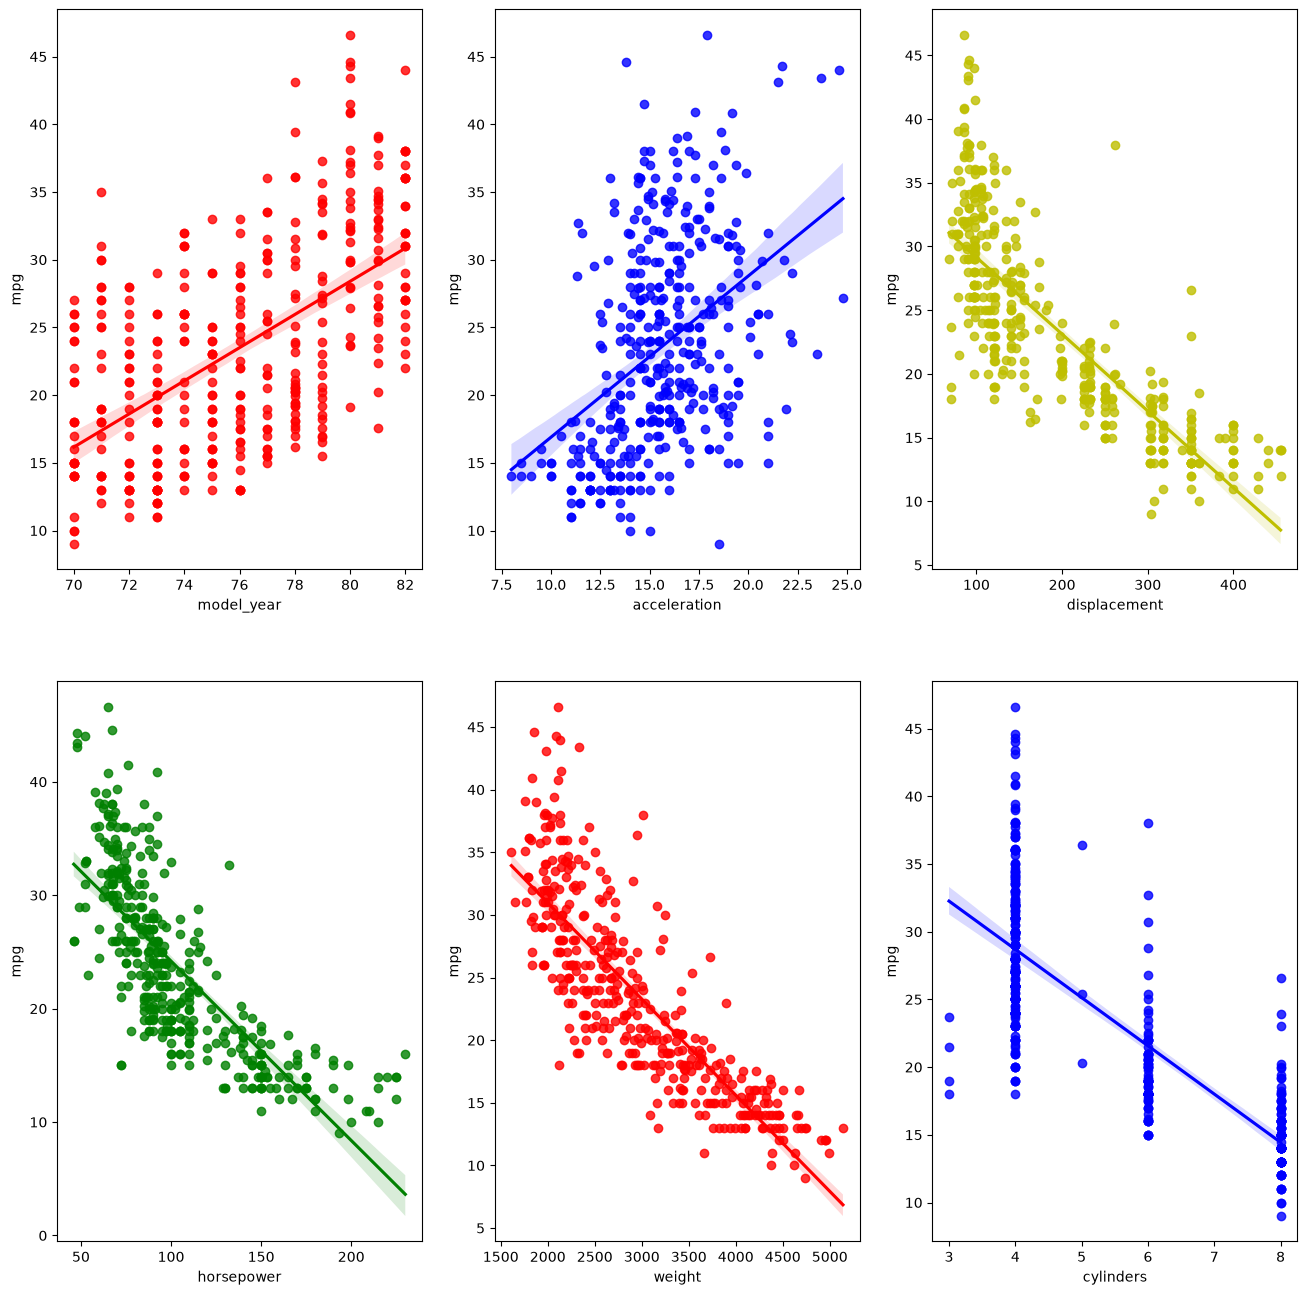

In [52]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axs = plt.subplots(figsize = (16, 16), ncols = 3, nrows = 2)
x_features = ['model_year', 'acceleration', 'displacement', 'horsepower', 'weight', 'cylinders']
plot_color = ['r', 'b', 'y', 'g', 'r', 'b']
for i, feature in enumerate(x_features):
    row = int(i/3)
    col = i%3
    sns.regplot(x = feature, y = 'mpg', data = data_df, ax = axs[row][col], color = plot_color[i])
plt.show()

In [54]:
print("연비를 예측하고 싶은 차의 정보를 입력해주세요.")
cylinders_1 = int(input("cylinders: "))
displacement_1 = int(input("displacement: "))
horse_power_1 = int(input("horse_power: "))
weight_1 = int(input("weight: "))
acceleration_1 = int(input("acceleration: "))
model_year_1 = int(input("model_year: "))

연비를 예측하고 싶은 차의 정보를 입력해주세요.


cylinders:  8
displacement:  350
horse_power:  150
weight:  3200
acceleration:  22
model_year:  99


In [58]:
mpg_predict = lr.predict([[cylinders_1, displacement_1, horse_power_1, weight_1, acceleration_1, model_year_1]])
print('type: ', type(mpg_predict))
print('shape: ', mpg_predict.shape)
print('이 자동차의 예상 연비(MPG)는 %.2f입니다.' % mpg_predict[0])

type:  <class 'numpy.ndarray'>
shape:  (1,)
이 자동차의 예상 연비(MPG)는 40.86입니다.


C:\Users\HP\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
